<a href="https://colab.research.google.com/github/iaryanMishra/DeepDetect-AI/blob/main/DeepDetect_FineTuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# step1

Mounted at /content/drive


In [ ]:
from google.colab import files
files.upload()

Saving kaggle (7).json to kaggle (7).json


{'kaggle (7).json': b'{"username":"aryanmishra73","key":"855fb0ed85601ef6bbe2d95ec073149e"}'}

In [ ]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json


In [ ]:
!kaggle datasets download -d ayushmandatta1/deepdetect-2025

Dataset URL: https://www.kaggle.com/datasets/ayushmandatta1/deepdetect-2025
License(s): apache-2.0
100% 3.23G/3.23G [02:44<00:00, 21.0MB/s]



In [ ]:
!rm -rf /content/ddata

In [ ]:
!unzip -q deepdetect-2025.zip -d /content/

In [ ]:
# !cp -r "/content/drive/MyDrive/DeepDetect_Project/Dataset/ddata" /content/

In [ ]:
!ls /content/ddata

test  train


In [ ]:
# # NO NEED TO RUN

# import shutil
# import os

# source = "/content/drive/MyDrive/DeepDetect_Project/Dataset/ddata"
# destination = "/content/ddata"

# if os.path.exists(destination):
#     shutil.rmtree(destination)

# shutil.copytree(source, destination)

# print("✅ Dataset copied successfully!")

# #  no need to re run ( same as upper coping cell)

In [ ]:
import imghdr
import os
                    #  step 2
removed = 0

for root, dirs, files in os.walk("/content/ddata"):
    for file in files:
        path = os.path.join(root, file)

        if imghdr.what(path) is None:
            os.remove(path)
            removed += 1
            print("Removed:", path)

print(f"\n✅ Total removed: {removed}")

/tmp/ipykernel_433/128030987.py:1: DeprecationWarning: 'imghdr' is deprecated and slated for removal in Python 3.13
  import imghdr


Removed: /content/ddata/train/fake/fake_040620.jpg
Removed: /content/ddata/train/fake/fake_015223.jpg
Removed: /content/ddata/test/real/real_050759.jpg
Removed: /content/ddata/test/real/real_046591.jpg
Removed: /content/ddata/test/real/real_054843.jpg
Removed: /content/ddata/test/real/real_047906.jpg
Removed: /content/ddata/test/real/real_052051.jpg
Removed: /content/ddata/test/real/real_051125.jpg
Removed: /content/ddata/test/real/real_054792.jpg
Removed: /content/ddata/test/real/real_046329.jpg
Removed: /content/ddata/test/real/real_056765.jpg
Removed: /content/ddata/test/real/real_056194.jpg
Removed: /content/ddata/test/real/real_053556.jpg
Removed: /content/ddata/test/real/real_051996.jpg
Removed: /content/ddata/test/real/real_048533.jpg
Removed: /content/ddata/test/real/real_049927.jpg
Removed: /content/ddata/test/real/real_050489.jpg
Removed: /content/ddata/test/real/real_050783.jpg
Removed: /content/ddata/test/real/real_047201.jpg
Removed: /content/ddata/test/real/real_052822.jp

In [ ]:
train_dir = "/content/ddata/train"
test_dir = "/content/ddata/test"

# step 3

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os


In [ ]:
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
SEED = 42

# step 4

In [ ]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

# step 5

Found 90407 files belonging to 2 classes.
Using 72326 files for training.


In [ ]:
validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

# step 6

Found 90407 files belonging to 2 classes.
Using 18081 files for validation.


In [ ]:
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE
)

# step 7

Found 21757 files belonging to 2 classes.


In [ ]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

# if error then re run

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/DeepDetect_Project/models/best_model.keras")

In [ ]:
# Find the EfficientNet backbone
base_model = None

for layer in model.layers:
    if "efficientnet" in layer.name.lower():
        base_model = layer
        break

print(base_model.name)

# Unfreeze the backbone
base_model.trainable = True

# Freeze all except the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

print("Trainable layers:",
      sum([layer.trainable for layer in base_model.layers]))

efficientnetb0
Trainable layers: 30


In [ ]:
import tensorflow as tf

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [ ]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
import os

save_dir = "/content/drive/MyDrive/DeepDetect_Project/models"
os.makedirs(save_dir, exist_ok=True)

checkpoint = ModelCheckpoint(
    filepath=os.path.join(save_dir, "final_model.keras"),
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_accuracy",
    patience=4,
    restore_best_weights=True,
    mode="max",
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

callbacks = [checkpoint, early_stop, reduce_lr]

In [ ]:
fine_tune_history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
4521/4521 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 0.7158 - auc: 0.7896 - loss: 0.5591
Epoch 1: val_accuracy improved from None to 0.83734, saving model to /content/drive/MyDrive/DeepDetect_Project/models/final_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/DeepDetect_Project/models/final_model.keras
4521/4521 ━━━━━━━━━━━━━━━━━━━━ 346s 72ms/step - accuracy: 0.7420 - auc: 0.8193 - loss: 0.5208 - val_accuracy: 0.8373 - val_auc: 0.9218 - val_loss: 0.3735 - learning_rate: 1.0000e-05
Epoch 2/10
4520/4521 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step - accuracy: 0.7899 - auc: 0.8713 - loss: 0.4473
Epoch 2: val_accuracy improved from 0.83734 to 0.86632, saving model to /content/drive/MyDrive/DeepDetect_Project/models/final_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/DeepDetect_Project/models/final_model.keras
4521/4521 ━━━━━━━━━━━━━━━━━━━━ 324s 72ms/step - accuracy: 0.7967 - auc: 0.8777 - loss: 0.4369 - val_accuracy: 0.8663 - val_auc: 0.947

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/drive/MyDrive/DeepDetect_Project/models/final_model.keras")

In [ ]:
test_loss, test_accuracy, test_auc = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test AUC:", test_auc)

1360/1360 ━━━━━━━━━━━━━━━━━━━━ 63s 46ms/step - accuracy: 0.8467 - auc: 0.9270 - loss: 0.3501
Test Loss: 0.35009345412254333
Test Accuracy: 0.8466700315475464
Test AUC: 0.9270490407943726


In [ ]:
y_true = np.concatenate([labels.numpy() for images, labels in test_dataset])

y_pred_prob = model.predict(test_dataset)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

1360/1360 ━━━━━━━━━━━━━━━━━━━━ 66s 47ms/step


In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_true = np.concatenate([labels.numpy() for images, labels in test_dataset])

y_pred_prob = model.predict(test_dataset)

y_pred = (y_pred_prob > 0.5).astype(int).flatten()

print(classification_report(
    y_true,
    y_pred,
    target_names=["fake", "real"]
))

1360/1360 ━━━━━━━━━━━━━━━━━━━━ 60s 44ms/step
              precision    recall  f1-score   support

        fake       0.81      0.88      0.85     10399
        real       0.88      0.82      0.85     11358

    accuracy                           0.85     21757
   macro avg       0.85      0.85      0.85     21757
weighted avg       0.85      0.85      0.85     21757



[[9142 1257]
 [2079 9279]]


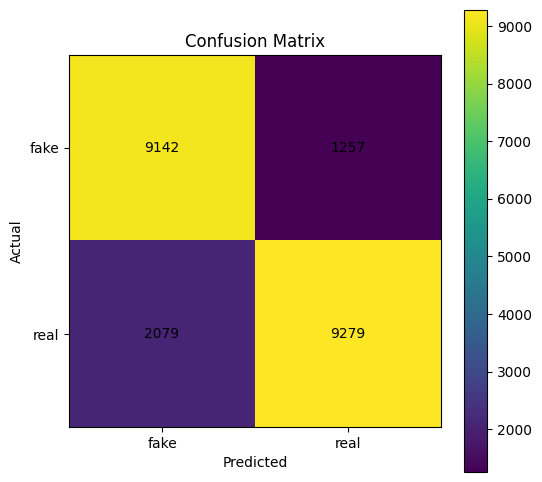

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

print(cm)

plt.figure(figsize=(6,6))
plt.imshow(cm, interpolation='nearest')
plt.title("Confusion Matrix")
plt.colorbar()

plt.xticks([0,1], ["fake","real"])
plt.yticks([0,1], ["fake","real"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i,j], ha="center", va="center")

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
temp_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMAGE_SIZE,
    batch_size=1,
    shuffle=False
)
class_names = temp_dataset.class_names
print(class_names)

Found 90407 files belonging to 2 classes.
['fake', 'real']
